# Tuning, bias-variance and interpretation

Three questions:
1. How much does tuning LightGBM help, and does a smart search (Bayesian, TPE) beat a random one with the same budget?
2. Are my best models limited by bias or by variance? (learning curves)
3. What drives the predictions, and where do the different importance tools disagree?

Same protocol as before: shared folds, 524 and 1299 out of training, scored on all houses.

In [1]:
# Make src/ importable from notebooks/ and reload edited modules automatically
%load_ext autoreload
%autoreload 2
import sys, pathlib, json, time, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
import shap
from lightgbm import LGBMRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso, Ridge
from sklearn.model_selection import KFold, learning_curve
from sklearn.pipeline import Pipeline, make_pipeline

from src.cv import RAW_DIR, FIGURES_DIR, RESULTS_PATH, SEED, CV, SCORING, evaluate_oof, fold_rmse, show_results
from src.features import make_linear_preprocessor, make_tree_preprocessor

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", message=".*does not have valid feature names.*")
optuna.logging.set_verbosity(optuna.logging.WARNING)

train = pd.read_csv(RAW_DIR / "train.csv")
X = train.drop(columns=["Id", "SalePrice"])
y = np.log1p(train["SalePrice"])
keep = ~train["Id"].isin([524, 1299]).to_numpy()
NO_OUT = "no 524/1299"

def prepare_folds(X, y, splits, keep):
    """Fit the tree preprocessor once per fold and cache the transformed data.

    The preprocessing doesn't depend on LightGBM's settings, so every tuning trial can reuse it.
    """
    out = []
    for tr_idx, va_idx in splits:
        tr_idx = tr_idx[keep[tr_idx]]
        prep = make_tree_preprocessor().fit(X.iloc[tr_idx])
        out.append((prep.transform(X.iloc[tr_idx]), y.iloc[tr_idx].to_numpy(),
                    prep.transform(X.iloc[va_idx]), y.iloc[va_idx].to_numpy()))
    return out

folds = prepare_folds(X, y, CV.split(X), keep)
print("cached", len(folds), "folds")

/home/fsa/Desktop/projects/House Prices - Advanced Regression Techniques/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cached 5 folds


The tree preprocessor is fitted once per fold and the transformed data is cached. Its result doesn't depend on LightGBM's settings, so every tuning trial reuses it and only fits LightGBM. The tqdm warning is harmless.

In [2]:
# The search space and the objective: mean RMSE over the shared folds
def lgbm_params(trial):
    return {
        "n_estimators": trial.suggest_int("n_estimators", 300, 3000, log=True),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 4, 64, log=True),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 50),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.2, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 10, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-4, 10, log=True),
    }

FIXED = {"subsample_freq": 1, "random_state": SEED, "verbose": -1}

def make_objective(fold_data):
    def objective(trial):
        params = {**lgbm_params(trial), **FIXED}
        scores = []
        for k, (Xtr, ytr, Xva, yva) in enumerate(fold_data):
            model = LGBMRegressor(**params).fit(Xtr, ytr)
            scores.append(np.sqrt(np.mean((yva - model.predict(Xva)) ** 2)))
            # Report the running mean so clearly bad trials can be stopped early (pruning)
            trial.report(float(np.mean(scores)), step=k)
            if trial.should_prune():
                raise optuna.TrialPruned()
        return float(np.mean(scores))
    return objective

8 hyperparameters, most on a log scale (learning rate, regularization, number of trees and leaves), because what matters for those is the order of magnitude. The objective is exactly the project's protocol: mean RMSE over the shared folds, with 524 and 1299 out of training.

After each fold the trial reports its running mean. If it's clearly worse than the median of earlier trials at the same fold, it's stopped (pruned). Every trial sees the folds in the same order, so the comparison is fair.

TPE (Bayesian)  best RMSE 0.1231 | 2.4 min | 2 of 60 trials pruned
Random          best RMSE 0.1244 | 2.8 min | 37 of 60 trials pruned


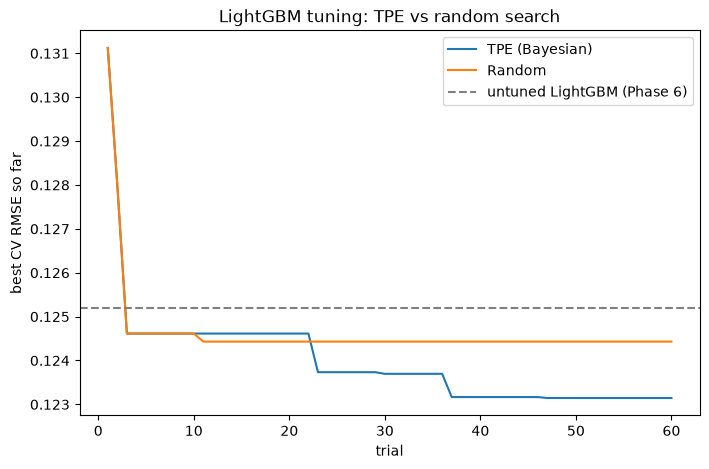

In [3]:
# Same budget for both: Bayesian search (TPE) vs pure random search
N_TRIALS = 60
studies, timings = {}, {}
for name, sampler in [("TPE (Bayesian)", optuna.samplers.TPESampler(seed=SEED)),
                      ("Random", optuna.samplers.RandomSampler(seed=SEED))]:
    study = optuna.create_study(direction="minimize", sampler=sampler,
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=1))
    t0 = time.time()
    study.optimize(make_objective(folds), n_trials=N_TRIALS)
    studies[name], timings[name] = study, time.time() - t0
    n_pruned = sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials)
    print(f"{name:15s} best RMSE {study.best_value:.4f} | {timings[name] / 60:.1f} min | {n_pruned} of {N_TRIALS} trials pruned")

# Best score found so far, trial by trial
fig, ax = plt.subplots(figsize=(8, 5))
for name, study in studies.items():
    # Pruned trials keep a partial score (mean of the first folds only), so only complete trials count
    values = [t.value if t.state == optuna.trial.TrialState.COMPLETE else np.nan for t in study.trials]
    best_so_far = pd.Series(values).ffill().cummin()
    ax.plot(range(1, len(best_so_far) + 1), best_so_far, label=name)
ax.axhline(0.1252, color="grey", ls="--", label="untuned LightGBM (Phase 6)")
ax.set(xlabel="trial", ylabel="best CV RMSE so far", title="LightGBM tuning: TPE vs random search")
ax.legend()
fig.savefig(FIGURES_DIR / "07_tuning_progress.png", dpi=150, bbox_inches="tight")
plt.show()

TPE finds the better settings: 0.1231 vs 0.1244 for random search, with the same 60 trials.

The pruning numbers show how they search differently. Random search had 37 of 60 trials pruned: it keeps landing in bad regions, and the pruner stops those early. TPE had only 2 pruned, because after the first few trials it concentrates on settings close to the good ones. Both took about the same time (2.4 and 2.9 minutes).

Correction on the plot: my first version counted pruned trials, and Optuna stores a pruned trial's partial score (the mean of only its first, easier folds). That made both curves dip below their real best near the end. The code now only counts complete trials; rerun this cell to refresh the plot. The real final values are the printed ones: 0.1231 and 0.1244.

The gain over untuned LightGBM (0.1252) is small either way.

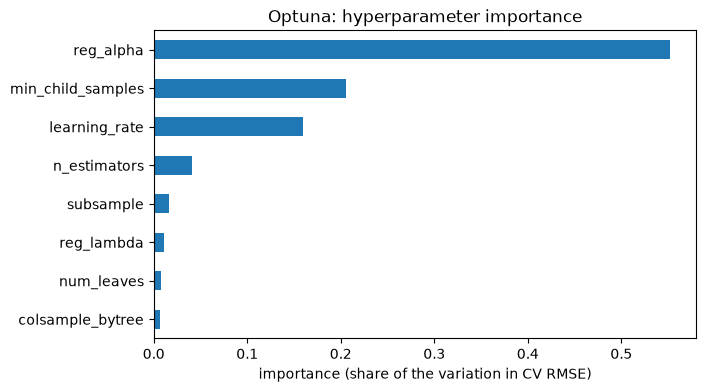

best parameters (TPE):
  n_estimators       827
  learning_rate      0.009753
  num_leaves         15
  min_child_samples  12
  subsample          0.622
  colsample_bytree   0.2678
  reg_alpha          0.02196
  reg_lambda         1.021


In [4]:
# Which hyperparameters actually mattered, and the best settings found
tpe = studies["TPE (Bayesian)"]
# fANOVA: fits a small random forest of "settings -> score" and measures each setting's share
evaluator = optuna.importance.FanovaImportanceEvaluator(seed=SEED)
importance = pd.Series(optuna.importance.get_param_importances(tpe, evaluator=evaluator)).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
importance.plot.barh(ax=ax)
ax.set(xlabel="importance (share of the variation in CV RMSE)", title="Optuna: hyperparameter importance")
fig.savefig(FIGURES_DIR / "07_param_importance.png", dpi=150, bbox_inches="tight")
plt.show()

best_params = tpe.best_params
print("best parameters (TPE):")
for k, v in best_params.items():
    print(f"  {k:18s} {v:.4g}" if isinstance(v, float) else f"  {k:18s} {v}")

reg_alpha explains more than half of the variation in score, then min_child_samples (0.21) and learning_rate (0.16). num_leaves, colsample_bytree and subsample barely matter.

This needs careful reading: importance means "how much the score changed across the range I searched", not "how important this setting is in general". reg_alpha went up to 10, and large values ruin the model, so most of its importance is really "don't set reg_alpha too high". With a narrower range it would look unimportant.

The best settings are close to the untuned ones from Phase 6: learning rate about 0.01, 15 leaves, min_child_samples 12. The main differences are fewer trees (827 instead of 2,000, very close to the 804 that early stopping picked in Phase 6) and stronger column subsampling (27% of the features per tree instead of 50%).

In [5]:
# The tuned LightGBM through the usual pipeline, logged.
# Caution: tuned and scored on the same folds, so slightly optimistic (see the nested check below).
tuned_lgbm = Pipeline([("prep", make_tree_preprocessor()), ("model", LGBMRegressor(**best_params, **FIXED))])
s_tuned, p_tuned = evaluate_oof(tuned_lgbm, X, y, f"LightGBM (Optuna, {N_TRIALS} trials)", f"tree_features, {NO_OUT}",
                                train_keep=keep, phase=7, n_features=91, params=best_params,
                                notes="tuned on the same folds")
# The untuned LightGBM from Phase 6, read back from results.csv
results = pd.read_csv(RESULTS_PATH)
untuned = np.array(json.loads(results.loc[results["model"] == "LightGBM", "fold_scores"].iloc[0]))
d = untuned - s_tuned
print(f"vs untuned LightGBM: mean diff {d.mean():+.4f} | better on {int((d > 0).sum())} of 5 folds")

LightGBM (Optuna, 60 trials) [tree_features, no 524/1299]: RMSE 0.1231 ± 0.0186 | folds [0.1314, 0.107, 0.154, 0.1213, 0.102]
vs untuned LightGBM: mean diff +0.0021 | better on 3 of 5 folds


Tuned LightGBM: 0.1231 ± 0.019, vs 0.1252 untuned. Better on 3 of 5 folds by 0.0021 on average. A real but small gain.

In [6]:
# Nested CV, once: the tuning runs INSIDE each outer training fold, on inner folds only.
# The outer validation fold never influences the chosen settings, so this score is honest.
N_INNER_TRIALS = 20
nested_scores, nested_preds = [], np.empty(len(y))
t0 = time.time()
for k, (tr_idx, va_idx) in enumerate(CV.split(X)):
    tr_keep = tr_idx[keep[tr_idx]]
    inner_cv = KFold(n_splits=3, shuffle=True, random_state=SEED)
    inner = prepare_folds(X.iloc[tr_keep], y.iloc[tr_keep], inner_cv.split(tr_keep), np.ones(len(tr_keep), bool))
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(make_objective(inner), n_trials=N_INNER_TRIALS)
    model = Pipeline([("prep", make_tree_preprocessor()),
                      ("model", LGBMRegressor(**study.best_params, **FIXED))]).fit(X.iloc[tr_keep], y.iloc[tr_keep])
    nested_preds[va_idx] = model.predict(X.iloc[va_idx])
nested_scores = fold_rmse(y, nested_preds)
print(f"nested CV:          {nested_scores.mean():.4f} ± {nested_scores.std():.4f} | folds {nested_scores.round(4).tolist()}")
print(f"tuned on same folds: {s_tuned.mean():.4f} ± {s_tuned.std():.4f}")
print(f"optimism of tuning on the same folds: {nested_scores.mean() - s_tuned.mean():+.4f} | {(time.time() - t0) / 60:.1f} min")

nested CV:          0.1242 ± 0.0191 | folds [0.1328, 0.1083, 0.1567, 0.1194, 0.104]
tuned on same folds: 0.1231 ± 0.0186
optimism of tuning on the same folds: +0.0011 | 1.8 min


With tuning done inside each training fold, the honest score is 0.1242. Tuning on the same folds overstated it by only 0.0011 this time.

So the honest gain from 60 rounds of tuning is about 0.001 (0.1252 to 0.1242). On a dataset this size, sensible defaults plus early stopping already get almost everything. Features and outlier handling moved the score far more than hyperparameters.

Ridge (alpha=8.38): train [0.0649, 0.094] -> CV [0.1493, 0.1136] (first and last size) | gap at full size 0.0196
LightGBM (tuned): train [0.0887, 0.0693] -> CV [0.1699, 0.1165] (first and last size) | gap at full size 0.0472


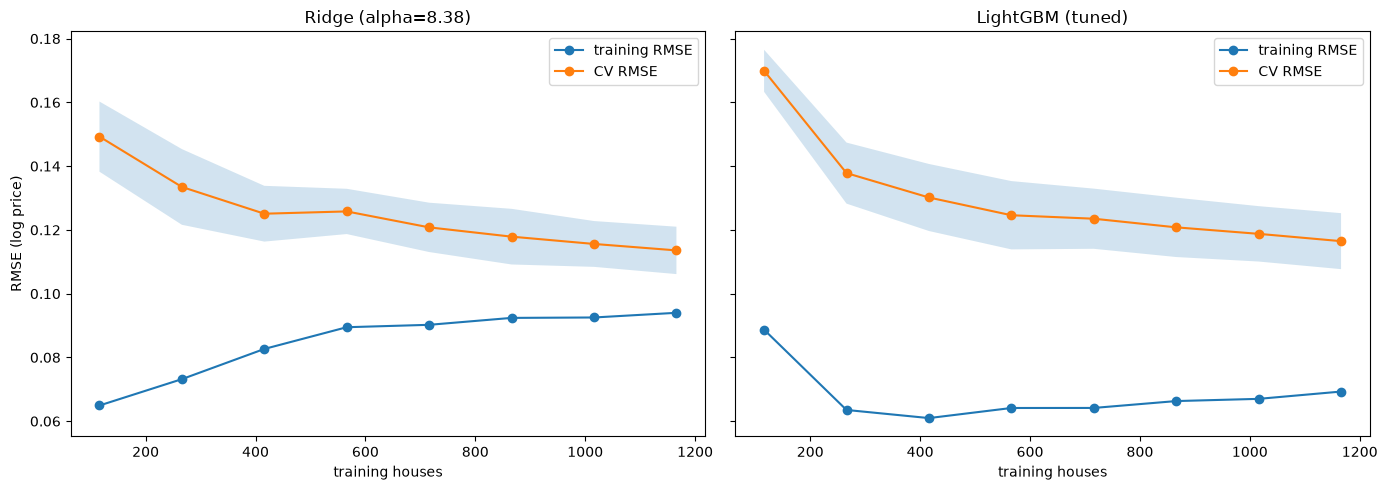

In [7]:
# Learning curves: training and CV error as the training set grows
sizes = np.linspace(0.1, 1.0, 8)
curves = {
    "Ridge (alpha=8.38)": make_pipeline(make_linear_preprocessor(), Ridge(alpha=8.38)),
    "LightGBM (tuned)": Pipeline([("prep", make_tree_preprocessor()), ("model", LGBMRegressor(**best_params, **FIXED))]),
}
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (name, model) in zip(axes, curves.items()):
    n, tr, cv = learning_curve(model, X[keep], y[keep], train_sizes=sizes, cv=CV, scoring=SCORING, n_jobs=1)
    tr, cv = -tr, -cv
    ax.plot(n, tr.mean(axis=1), marker="o", label="training RMSE")
    ax.plot(n, cv.mean(axis=1), marker="o", label="CV RMSE")
    ax.fill_between(n, cv.mean(axis=1) - cv.std(axis=1), cv.mean(axis=1) + cv.std(axis=1), alpha=0.2)
    ax.set(xlabel="training houses", title=name)
    ax.legend()
    print(f"{name}: train {tr.mean(axis=1)[[0, -1]].round(4).tolist()} -> CV {cv.mean(axis=1)[[0, -1]].round(4).tolist()} "
          f"(first and last size) | gap at full size {cv.mean(axis=1)[-1] - tr.mean(axis=1)[-1]:.4f}")
axes[0].set_ylabel("RMSE (log price)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "07_learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

Ridge: the training error rises (0.065 to 0.094) and the CV error falls (0.149 to 0.114) as data grows, and they end close together (gap 0.020). The CV curve is flattening, so more data would help only a little. Ridge is mostly limited by bias: to improve it I'd need more flexible features, not more houses.

LightGBM: the training error stays low (about 0.06 to 0.07) and the gap is much bigger (0.047), with the CV error still going down at full size. LightGBM is more limited by variance: more data would still help, or stronger regularization.

These curves are scored without 524 and 1299 in the data, and here Ridge (0.114) is slightly better than LightGBM (0.117) at full size. That matches Phase 6: on normal houses the linear model is just as good, and the boosters' lead in the main table comes mostly from the fold with the two outliers.

In [8]:
# Interpretation tool 1 and 2: Lasso coefficients and LightGBM split-gain importance
# Final models fitted on all training houses (without 524/1299)
lasso = make_pipeline(make_linear_preprocessor(), Lasso(alpha=0.000924, max_iter=20000)).fit(X[keep], y[keep])
lasso_names = [n.split("__", 1)[1] for n in lasso[0].named_steps["columns"].get_feature_names_out()]
lasso_coef = pd.Series(lasso[-1].coef_, index=lasso_names)

tree_prep = make_tree_preprocessor().fit(X[keep])
tree_names = [n.split("__", 1)[1] for n in tree_prep.named_steps["columns"].get_feature_names_out()]
Xt = pd.DataFrame(tree_prep.transform(X[keep]), columns=tree_names)
final_lgbm = LGBMRegressor(**best_params, **FIXED, importance_type="gain").fit(Xt, y[keep])
gain = pd.Series(final_lgbm.feature_importances_, index=tree_names)

print("Lasso, largest |coefficients| (standardized features):")
print(lasso_coef.reindex(lasso_coef.abs().sort_values(ascending=False).index).head(10).round(4).to_string())
print("\nLightGBM split gain (share of total):")
print((gain / gain.sum()).sort_values(ascending=False).head(10).round(3).to_string())

Lasso, largest |coefficients| (standardized features):
MSZoning_C (all)       -0.2091
GrLivArea               0.0911
Neighborhood_Crawfor    0.0844
OverallQual             0.0733
Functional_Typ          0.0612
Neighborhood_StoneBr    0.0531
SaleType_New            0.0513
OverallCond             0.0496
Exterior1st_BrkFace     0.0455
TotalSF                 0.0451

LightGBM split gain (share of total):
QualxArea      0.244
OverallQual    0.136
TotalSF        0.112
ExterQual      0.038
GrLivArea      0.037
YearBuilt      0.033
GarageCars     0.031
TotalBath      0.029
KitchenQual    0.029
HouseAge       0.024


Lasso's top coefficients are dominated by one-hot categories: MSZoning_C (all) (-0.21, houses in commercial zones sell about 19% lower), Crawfor and StoneBr (positive), Functional_Typ, SaleType_New. The one-hot columns aren't standardized, so their coefficient is the effect of having that category, while numeric coefficients are per standard deviation. The two aren't on the same scale, so this ranking favors rare but strong categories over features that affect every house.

LightGBM's split gain is led by QualxArea (24%), OverallQual (14%) and TotalSF (11%). The engineered features do a lot of the work inside the trees.

In [9]:
# Interpretation tool 3: permutation importance on held-out data (any model, raw input columns).
# For each fold: fit on the training part, then shuffle one raw column at a time in the validation
# part and measure how much the RMSE gets worse.
perm = []
for tr_idx, va_idx in CV.split(X):
    tr_idx = tr_idx[keep[tr_idx]]
    va_idx = va_idx[keep[va_idx]]
    model = Pipeline([("prep", make_tree_preprocessor()),
                      ("model", LGBMRegressor(**best_params, **FIXED))]).fit(X.iloc[tr_idx], y.iloc[tr_idx])
    r = permutation_importance(model, X.iloc[va_idx], y.iloc[va_idx], scoring=SCORING,
                               n_repeats=3, random_state=SEED)
    perm.append(pd.Series(r.importances_mean, index=X.columns))
perm = pd.concat(perm, axis=1).mean(axis=1).sort_values(ascending=False)
print("increase in RMSE when the column is shuffled:")
print(perm.head(10).round(4).to_string())

increase in RMSE when the column is shuffled:
OverallQual     0.0499
GrLivArea       0.0423
TotalBsmtSF     0.0181
2ndFlrSF        0.0115
1stFlrSF        0.0113
YearBuilt       0.0107
OverallCond     0.0082
YearRemodAdd    0.0058
LotArea         0.0042
Fireplaces      0.0031


Permutation importance works on the raw input columns, so engineered features can't appear. Their importance is credited to the raw columns they're built from: shuffling OverallQual also scrambles QualxArea, and shuffling TotalBsmtSF, 1stFlrSF or 2ndFlrSF scrambles TotalSF.

That's why OverallQual (0.050) and GrLivArea (0.042) lead, followed by the three area columns, YearBuilt and OverallCond. The numbers are the increase in RMSE on held-out houses when the column is shuffled.

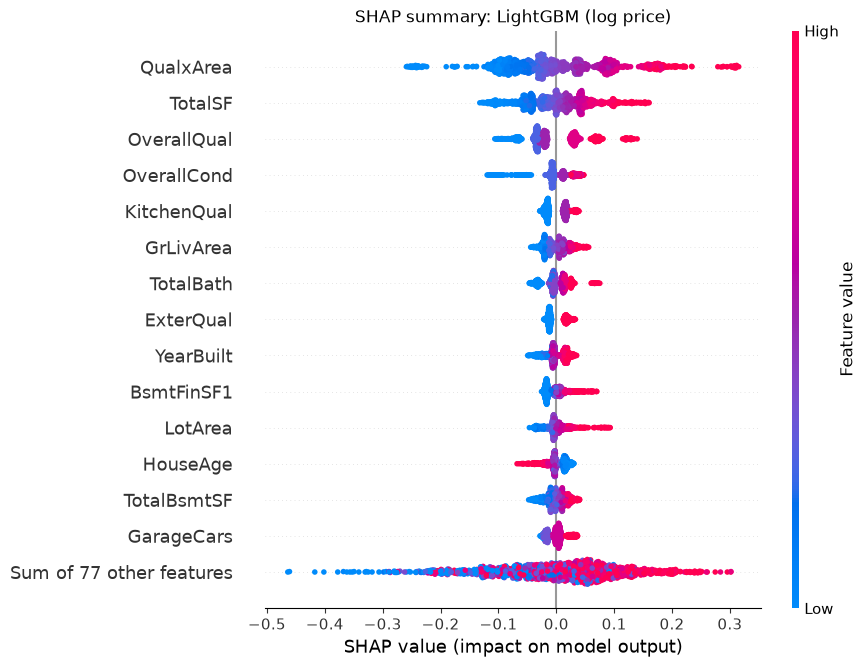

            Lasso |coef| LightGBM gain permutation (raw)  mean |SHAP|
1       MSZoning_C (all)     QualxArea       OverallQual    QualxArea
2              GrLivArea   OverallQual         GrLivArea      TotalSF
3   Neighborhood_Crawfor       TotalSF       TotalBsmtSF  OverallQual
4            OverallQual     ExterQual          2ndFlrSF  OverallCond
5         Functional_Typ     GrLivArea          1stFlrSF  KitchenQual
6   Neighborhood_StoneBr     YearBuilt         YearBuilt    GrLivArea
7           SaleType_New    GarageCars       OverallCond    TotalBath
8            OverallCond     TotalBath      YearRemodAdd    ExterQual
9    Exterior1st_BrkFace   KitchenQual           LotArea    YearBuilt
10               TotalSF      HouseAge        Fireplaces   BsmtFinSF1


In [10]:
# Interpretation tool 4: SHAP values for LightGBM (one contribution per feature per house)
explainer = shap.TreeExplainer(final_lgbm)
sv = explainer(Xt)

shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title("SHAP summary: LightGBM (log price)")
plt.gcf().savefig(FIGURES_DIR / "07_shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

mean_abs_shap = pd.Series(np.abs(sv.values).mean(axis=0), index=tree_names).sort_values(ascending=False)

# The four tools side by side: top 10 of each
top10 = pd.DataFrame({
    "Lasso |coef|": lasso_coef.abs().sort_values(ascending=False).index[:10],
    "LightGBM gain": gain.sort_values(ascending=False).index[:10],
    "permutation (raw)": perm.index[:10],
    "mean |SHAP|": mean_abs_shap.index[:10],
}, index=range(1, 11))
print(top10.to_string())

SHAP: QualxArea has the widest spread, from about -0.25 to +0.3 in log price (roughly -22% to +35%). Then TotalSF and OverallQual. High values (red) push the price up and low values (blue) push it down, as expected.

OverallCond is asymmetric: poor condition costs up to 12%, good condition adds only a few percent. HouseAge works the other way round: older houses (red) get negative contributions.

"Sum of 77 other features" has a wide spread too: many small effects add up.

Where the four tools agree: quality and size dominate.

Where they disagree, and why:
- Engineered vs raw: gain and SHAP credit QualxArea and TotalSF; permutation credits the raw columns they're built from.
- Lasso ranks rare one-hot categories (commercial zoning, specific neighborhoods) high because of the scale difference.
- Neighborhood matters for Lasso but doesn't make the tree top 10: the trees get it as an integer code, which is harder to use, and quality and age already carry part of the location information.

No single importance ranking is "the truth"; each answers a slightly different question.

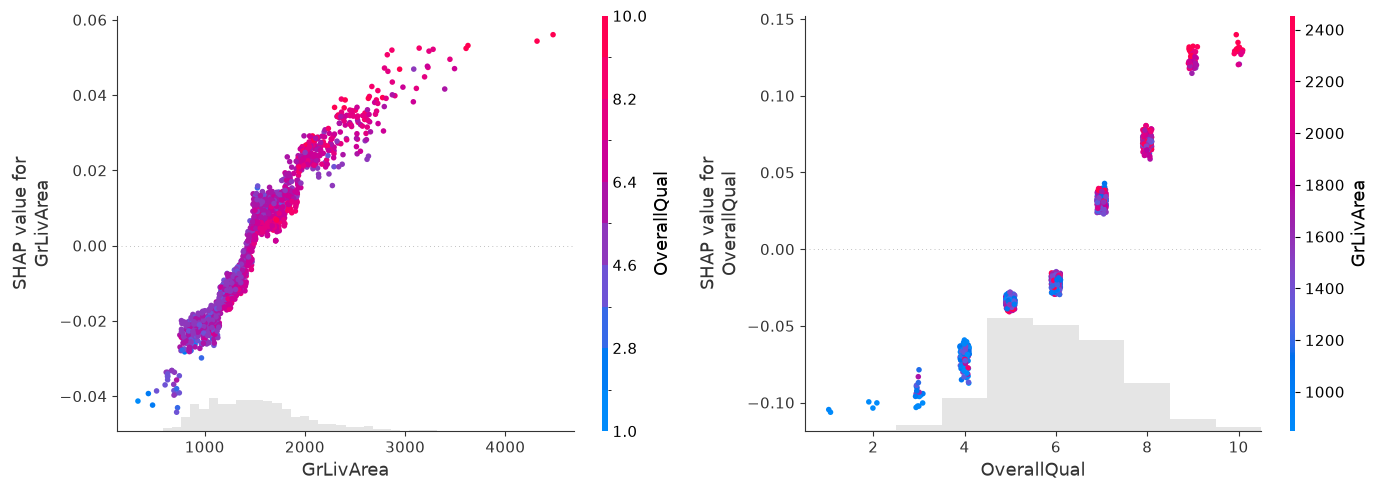

In [11]:
# SHAP dependence: how the contribution of one feature changes with its value
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
shap.plots.scatter(sv[:, "GrLivArea"], color=sv[:, "OverallQual"], ax=axes[0], show=False)
shap.plots.scatter(sv[:, "OverallQual"], color=sv[:, "GrLivArea"], ax=axes[1], show=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "07_shap_dependence.png", dpi=150, bbox_inches="tight")
plt.show()

GrLivArea: its contribution rises almost in a straight line, from about -0.04 at 700 sq ft to +0.055 at 4,500. That's on top of what QualxArea already carries. The colors show that the larger houses are also the higher-quality ones.

OverallQual: steps that get bigger toward the top. Levels 1 to 4 are all around -0.07 to -0.10, then -0.035 (5), -0.02 (6), +0.03 (7), +0.07 (8) and +0.13 (9 and 10). That's exactly the curve the linear model missed in Phase 4 (the U-shaped residuals for quality): the tree learns it on its own.

most expensive: Id 692 | actual $755,000 | predicted $625,102 | average prediction $166,682


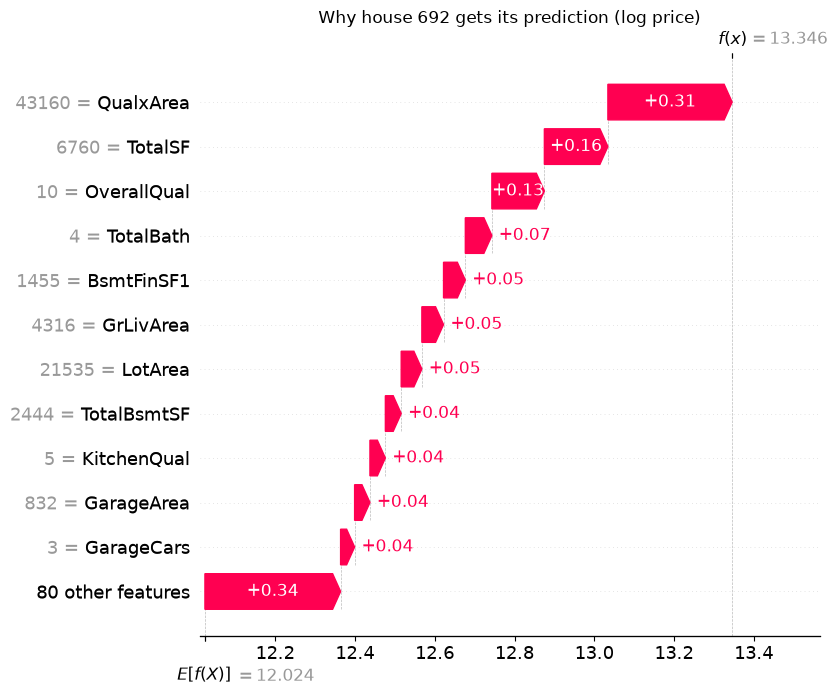

cheapest: Id 496 | actual $34,900 | predicted $50,079 | average prediction $166,682


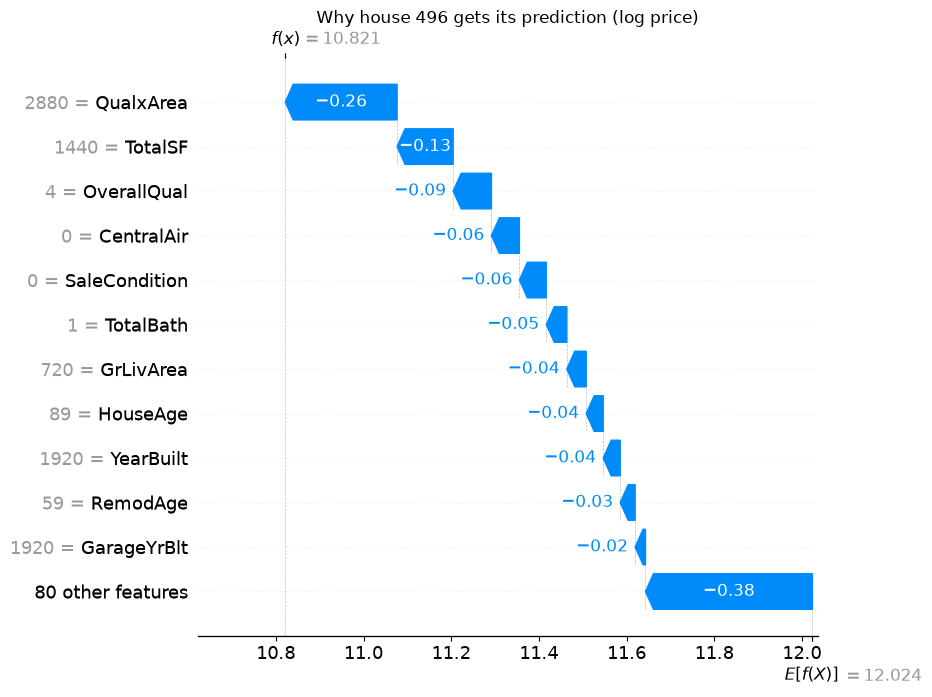

In [12]:
# Explaining single predictions: the most expensive and the cheapest house
prices = train.loc[keep, "SalePrice"].reset_index(drop=True)
ids = train.loc[keep, "Id"].reset_index(drop=True)
for label, i in [("most expensive", int(prices.idxmax())), ("cheapest", int(prices.idxmin()))]:
    pred = np.expm1(sv[i].base_values + sv[i].values.sum())
    print(f"{label}: Id {ids[i]} | actual ${prices[i]:,.0f} | predicted ${pred:,.0f} | "
          f"average prediction ${np.expm1(sv[i].base_values):,.0f}")
    shap.plots.waterfall(sv[i], max_display=12, show=False)
    plt.title(f"Why house {ids[i]} gets its prediction (log price)")
    plt.gcf().savefig(FIGURES_DIR / f"07_shap_waterfall_{ids[i]}.png", dpi=150, bbox_inches="tight")
    plt.show()

Every prediction starts from the same base value, 12.024 in log price (about \$167k), and each feature adds or subtracts. In dollars the contributions multiply: +0.31 in log means about 36% higher.

The base (\$167k) is lower than the average price in the data (about \$180k). The model averages log prices, and exp(average of logs) is always below the average price. That's why converting predictions back with expm1 gives something closer to a median than a mean.

House 692, the most expensive (\$755k): predicted \$625k, 17% too low. QualxArea (+0.31), TotalSF (+0.16) and OverallQual (+0.13) push it up, plus many small effects (+0.34 from the other 80 features). Trees can't go beyond the prices they've seen, so the most expensive houses tend to be under-predicted.

House 496, the cheapest (\$34,900): predicted \$50k, 43% too high. Small and low quality (QualxArea -0.26, TotalSF -0.13), no central air (-0.06), built in 1920, one bathroom. SaleCondition = 0 is the integer code for "Abnorml" (an abnormal sale), which also pulls it down by 6%. The integer codes are one downside of ordinal encoding: the plot shows 0 instead of the category name.

In [13]:
# The results table so far
print(show_results().head(15).to_string())

    phase                                        model                         feature_set  n_features  cv_rmse_mean  cv_rmse_std                                              notes
0       6                                     CatBoost    native categoricals, no 524/1299          91       0.12191      0.01456            untuned; 31 categorical columns as text
1       6                                      XGBoost          tree_features, no 524/1299          91       0.12205      0.01938                                            untuned
2       7                 LightGBM (Optuna, 60 trials)          tree_features, no 524/1299          91       0.12315      0.01862                            tuned on the same folds
3       6                                     LightGBM          tree_features, no 524/1299          91       0.12520      0.02065                                            untuned
4       6                       SVR (C=3, gamma=0.001)            linear_full, no 524/1299     

Top 3: CatBoost (0.1219) and XGBoost (0.1220), both untuned, then tuned LightGBM (0.1231; 0.1242 nested). All within the fold noise of each other.

## Where I am after Phase 7

Tuning: TPE beat random search with the same budget (0.1231 vs 0.1244), and pruning saved time by stopping bad trials early. The honest gain from tuning LightGBM is about 0.001 (nested CV 0.1242 vs 0.1252 untuned). Tuning on the same folds overstated it by 0.0011. The best settings are close to the defaults I started with, with fewer trees and more column subsampling.

Bias vs variance: Ridge is near its bias limit (small gap, flat curves). LightGBM has a bigger gap and would gain more from extra data or regularization. On normal houses Ridge is just as good as LightGBM.

Interpretation: all four tools agree that quality and size drive the price. They disagree on the details for understandable reasons: raw vs engineered features, unscaled one-hot coefficients in Lasso, and integer-coded neighborhoods for the trees. SHAP shows the curve in OverallQual that the linear model missed.

Next, Phase 8: blending linear and tree models, error analysis, and the final Kaggle submission.